In [1]:

import pandas as pd
from google.colab import files
import io

# Upload your CSV file
uploaded = files.upload()

# Read the uploaded file
df = pd.read_csv(
    io.BytesIO(uploaded["IMDb Movies India.csv"]),
    encoding="latin1"
)

# Display the dataset
print("File imported successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Saving IMDb Movies India.csv to IMDb Movies India.csv
File imported successfully!
Dataset shape: (15509, 10)


,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,,NaN,NaN,Drama,NaN,NaN,J.S. Randhawa,Manmauji,Birbal,Rajendra Bhatia
1,#Gadhvi (He thought he was Gandhi),(2019),109 min,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
2,#Homecoming,(2021),90 min,"Drama, Musical",NaN,NaN,Soumyajit Majumdar,Sayani Gupta,Plabita Borthakur,Roy Angana
3,#Yaaram,(2019),110 min,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
4,...And Once Again,(2010),105 min,Drama,NaN,NaN,Amol Palekar,Rajat Kapoor,Rituparna Sengupta,Antara Mali


In [3]:

# Keep movies with a known rating
df = df.dropna(subset=["Rating"]).copy()

# Convert rating into a numeric value
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
df = df.dropna(subset=["Rating"])

# Convert text-based numbers into numeric values
df["Year"] = pd.to_numeric(
    df["Year"].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce"
)

df["Duration"] = pd.to_numeric(
    df["Duration"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

df["Votes"] = pd.to_numeric(
    df["Votes"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

print("Cleaned dataset shape:", df.shape)
display(df.head())


Cleaned dataset shape: (7919, 10)


,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
1,#Gadhvi (He thought he was Gandhi),2019,109.0,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
3,#Yaaram,2019,110.0,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
5,...Aur Pyaar Ho Gaya,1997,147.0,"Comedy, Drama, Musical",4.7,827,Rahul Rawail,Bobby Deol,Aishwarya Rai Bachchan,Shammi Kapoor
6,...Yahaan,2005,142.0,"Drama, Romance, War",7.4,1086,Shoojit Sircar,Jimmy Sheirgill,Minissha Lamba,Yashpal Sharma
8,?: A Question Mark,2012,82.0,"Horror, Mystery, Thriller",5.6,326,Allyson Patel,Yash Dave,Muntazir Ahmad,Kiran Bhatia


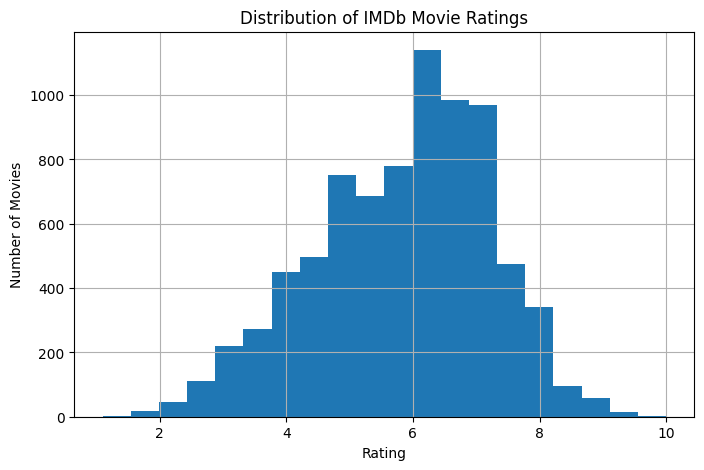

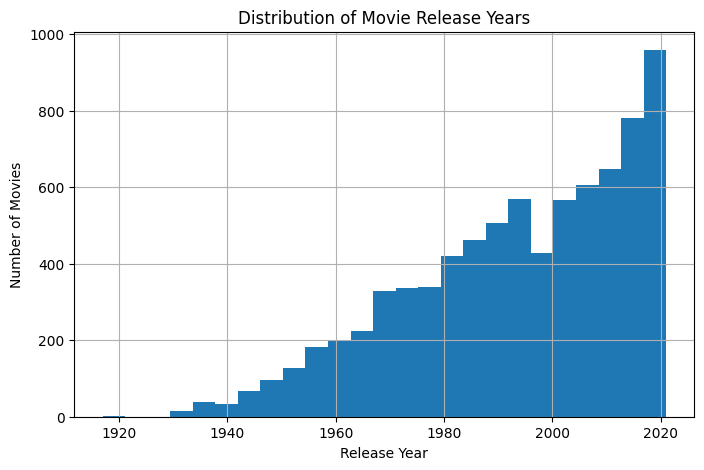

Average movie rating: 5.84
Median movie rating: 6.0


In [4]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
df["Rating"].hist(bins=20)
plt.title("Distribution of IMDb Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Movies")
plt.show()

plt.figure(figsize=(8, 5))
df["Year"].dropna().hist(bins=25)
plt.title("Distribution of Movie Release Years")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.show()

print("Average movie rating:", round(df["Rating"].mean(), 2))
print("Median movie rating:", round(df["Rating"].median(), 2))


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select input features and target
numeric_features = ["Year", "Duration", "Votes"]
categorical_features = [
    "Genre", "Director", "Actor 1", "Actor 2", "Actor 3"
]

features = numeric_features + categorical_features
X = df[features]
y = df["Rating"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Handle missing values and encode text columns
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore", min_frequency=15
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Build the model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

# Train
model.fit(X_train, y_train)

print("Model training completed successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Model training completed successfully!
Training samples: 6335
Testing samples: 1584


In [6]:

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error (MAE):", round(mae, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))
print("R-squared Score:", round(r2, 3))

results = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": np.round(predictions, 2)
})

display(results.head(10))


Mean Absolute Error (MAE): 0.846
Root Mean Squared Error (RMSE): 1.122
R-squared Score: 0.323


,Actual Rating,Predicted Rating
0,3.3,3.95
1,5.3,4.83
2,5.7,6.23
3,7.2,5.53
4,3.5,4.86
5,7.2,6.20
6,3.8,5.23
7,6.9,6.98
8,5.2,5.71
9,7.4,5.98


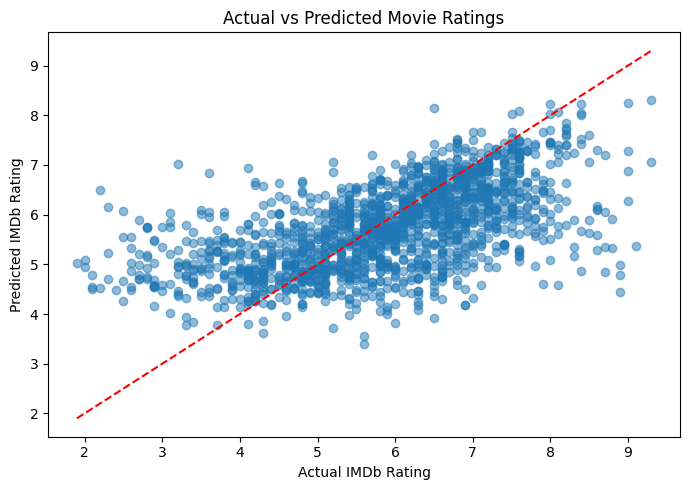

In [7]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, predictions, alpha=0.5)

plt.xlabel("Actual IMDb Rating")
plt.ylabel("Predicted IMDb Rating")
plt.title("Actual vs Predicted Movie Ratings")

# Reference line
low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())
plt.plot([low, high], [low, high], "r--")

plt.tight_layout()
plt.show()


In [8]:

import joblib

# Save trained model
joblib.dump(model, "/content/movie_rating_model.pkl")

# Save actual and predicted ratings
results.to_csv("/content/movie_rating_predictions.csv", index=False)

print("Saved:")
print("1. movie_rating_model.pkl")
print("2. movie_rating_predictions.csv")


Saved:
1. movie_rating_model.pkl
2. movie_rating_predictions.csv
